In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import matplotlib.ticker as ticker
import matplotlib.cm as cm
from warnings import filterwarnings
filterwarnings('ignore')

In [2]:
# Setting professional color theme 

plt.style.use('dark_background')
sns.set_palette("plasma")

plasma_colors = sns.color_palette("plasma", 5)

primary_color = '#C470FF'
secondary_color = '#00A1C2'
accent_color = '#FDFF70'
danger_color = '#FF0000'
neutral_color = '#b3b3b3'
custom_pallette = plasma_colors

In [3]:
df = pd.read_csv('SupplyChainData.csv', encoding='latin-1')

In [4]:
df.columns

Index(['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)',
       'Benefit per order', 'Sales per customer', 'Delivery Status',
       'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City',
       'Customer Country', 'Customer Email', 'Customer Fname', 'Customer Id',
       'Customer Lname', 'Customer Password', 'Customer Segment',
       'Customer State', 'Customer Street', 'Customer Zipcode',
       'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market',
       'Order City', 'Order Country', 'Order Customer Id',
       'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id',
       'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id',
       'Order Item Product Price', 'Order Item Profit Ratio',
       'Order Item Quantity', 'Sales', 'Order Item Total',
       'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status',
       'Order Zipcode', 'Product Card Id', 'Product Category Id',
       'Product De

## Exploratory Data Analysis (EDA)

In [5]:
# Overview
print('rows, cols:', df.shape)
print('\ncolumns:')
print(df.columns.tolist())
print('\nNum Duplicates:', df.duplicated().sum())
print('\nMissing values (top 20): ')
print(df.isna().sum().sort_values(ascending=False).head(20))

rows, cols: (180519, 53)

columns:
['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Delivery Status', 'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City', 'Customer Country', 'Customer Email', 'Customer Fname', 'Customer Id', 'Customer Lname', 'Customer Password', 'Customer Segment', 'Customer State', 'Customer Street', 'Customer Zipcode', 'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market', 'Order City', 'Order Country', 'Order Customer Id', 'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status', 'Order Zipcode', 'Product Card Id', 'Product Category Id', 'Product Description', 'Product Image', 'Product Name', 'Product Price', 'Produc

In [6]:
(df['Benefit per order'] == df['Order Profit Per Order']).value_counts()

True    180519
Name: count, dtype: int64

In [7]:
# Data Cleaning
columns_to_drop =['Product Description', 
                  'Product Image', 
                  'Customer Email', 
                  'Customer Password', 
                  'Customer Fname',
                  'Customer Lname', 
                  'Customer Street',
                  'Customer Zipcode',
                  'Order Zipcode', 
                  'Latitude', 
                  'Longitude',  
                  'Order Item Cardprod Id', 
                  'Order Item Id', 
                  'Order Item Discount', 
                  'Order Item Discount Rate',  
                  'Order Item Product Price',
                  'Order Item Quantity', 
                  'Order Item Total', 
                  'Category Id', 
                  'Department Id',
                  'Order Id',
                  'Order Customer Id',
                  'Customer Id',
                  'Product Card Id', 
                  'Product Category Id',
                  'Benefit per order', 
                  'Product Status', 
                  'Customer City',
                  'Order City',
                  'Order Country', 
                  'Order State',
                  'Customer State', 
                  'Market']

# Dropping columns that are either fully missing, redundant, or have only one value (and thus no variance)
df = df.drop(columns=columns_to_drop)

# removing canceled orders since they are not relevant for 
# delivery time analysis and may have different patterns than completed orders
df = df[df['Delivery Status'] != 'Shipping canceled']

# Standard date conversion
for c in ['order date (DateOrders)', 'shipping date (DateOrders)']:
    df[c] = pd.to_datetime(df[c], errors='coerce', dayfirst=False)

    
print('rows, cols:', df.shape)
print('\nMissing values (top 5): ')
print(df.isna().sum().sort_values(ascending=False).head(5))

rows, cols: (172765, 20)

Missing values (top 5): 
Type                          0
Days for shipping (real)      0
shipping date (DateOrders)    0
Product Price                 0
Product Name                  0
dtype: int64


In [8]:
df.head()

,Type,Days for shipping (real),Days for shipment (scheduled),Sales per customer,Delivery Status,Late_delivery_risk,Category Name,Customer Country,Customer Segment,Department Name,order date (DateOrders),Order Item Profit Ratio,Sales,Order Profit Per Order,Order Region,Order Status,Product Name,Product Price,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,314.640015,Advance shipping,0,Sporting Goods,Puerto Rico,Consumer,Fitness,2018-01-31 22:56:00,0.29,327.75,91.250000,Southeast Asia,COMPLETE,Smart watch,327.75,2018-02-03 22:56:00,Standard Class
1,TRANSFER,5,4,311.359985,Late delivery,1,Sporting Goods,Puerto Rico,Consumer,Fitness,2018-01-13 12:27:00,-0.80,327.75,-249.089996,South Asia,PENDING,Smart watch,327.75,2018-01-18 12:27:00,Standard Class
2,CASH,4,4,309.720001,Shipping on time,0,Sporting Goods,EE. UU.,Consumer,Fitness,2018-01-13 12:06:00,-0.80,327.75,-247.779999,South Asia,CLOSED,Smart watch,327.75,2018-01-17 12:06:00,Standard Class
3,DEBIT,3,4,304.809998,Advance shipping,0,Sporting Goods,EE. UU.,Home Office,Fitness,2018-01-13 11:45:00,0.08,327.75,22.860001,Oceania,COMPLETE,Smart watch,327.75,2018-01-16 11:45:00,Standard Class
4,PAYMENT,2,4,298.250000,Advance shipping,0,Sporting Goods,Puerto Rico,Corporate,Fitness,2018-01-13 11:24:00,0.45,327.75,134.210007,Oceania,PENDING_PAYMENT,Smart watch,327.75,2018-01-15 11:24:00,Standard Class


In [9]:
# Value counts for categorical columns with low cardinality
for i in df.columns:
    if df[i].nunique() < 10:
        print(f'\n{i} value counts:')
        print(df[i].value_counts())


Type value counts:
Type
DEBIT       69295
TRANSFER    42129
PAYMENT     41725
CASH        19616
Name: count, dtype: int64

Days for shipping (real) value counts:
Days for shipping (real)
2    54205
6    27489
3    27478
4    27297
5    27003
0     4839
1     4454
Name: count, dtype: int64

Days for shipment (scheduled) value counts:
Days for shipment (scheduled)
4    103153
2     33806
1     26513
0      9293
Name: count, dtype: int64

Delivery Status value counts:
Delivery Status
Late delivery       98977
Advance shipping    41592
Shipping on time    32196
Name: count, dtype: int64

Late_delivery_risk value counts:
Late_delivery_risk
1    98977
0    73788
Name: count, dtype: int64

Customer Country value counts:
Customer Country
EE. UU.        106425
Puerto Rico     66340
Name: count, dtype: int64

Customer Segment value counts:
Customer Segment
Consumer       89420
Corporate      52528
Home Office    30817
Name: count, dtype: int64

Order Status value counts:
Order Status
COMPLETE  

In [10]:
# Calculating order processing time and delay
df['Order Processing Time'] = (df['shipping date (DateOrders)'] - df['order date (DateOrders)']).dt.days
df['Delay'] = df['Order Processing Time'] - df['Days for shipment (scheduled)']
df['Is_Delayed'] = df['Delay']>0
df['order_month'] = df['order date (DateOrders)'].dt.month
df['order_day'] = df['order date (DateOrders)'].dt.day_name()
df['order_hour'] = df['order date (DateOrders)'].dt.hour
df.describe().T

,count,mean,min,25%,50%,75%,max,std
Days for shipping (real),172765.0,3.498596,0.0,2.0,3.0,5.0,6.0,1.623446
Days for shipment (scheduled),172765.0,2.9331,0.0,2.0,4.0,4.0,4.0,1.373405
Sales per customer,172765.0,183.165948,7.49,104.379997,163.990005,247.399994,1939.98999,120.141871
Late_delivery_risk,172765.0,0.5729,0.0,0.0,1.0,1.0,1.0,0.494659
order date (DateOrders),172765,2016-06-12 15:25:39.457991936,2015-01-01 00:00:00,2015-09-21 18:01:00,2016-06-11 08:11:00,2017-02-28 21:08:00,2018-01-31 23:38:00,NaN
Order Item Profit Ratio,172765.0,0.120801,-2.75,0.08,0.27,0.36,0.5,0.46661
Sales,172765.0,203.828493,9.99,119.980003,199.919998,299.950012,1999.98999,132.39252
Order Profit Per Order,172765.0,22.03236,-4274.97998,7.03,31.52,64.800003,911.799988,104.355313
Product Price,172765.0,141.278595,9.99,50.0,59.990002,199.990005,1999.98999,139.862956
shipping date (DateOrders),172765,2016-06-16 03:25:14.452927488,2015-01-03 00:00:00,2015-09-25 08:59:00,2016-06-15 03:38:00,2017-03-04 08:00:00,2018-02-06 22:14:00,NaN


In [11]:
df['Is_Delayed'].value_counts()

Is_Delayed
True     94523
False    78242
Name: count, dtype: int64

In [12]:
# Correcting column names
df.columns = df.columns.str.lower().str.replace(' ', '_')

In [13]:
# Profitability Flag based in Order Profit Per Order
df['profitability_flag'] = np.where(df['order_profit_per_order'] > 0, 'Profit', np.where(df['order_profit_per_order'] < 0, 'Loss', 'Break_even'))
df['profitability_flag'].value_counts()

profitability_flag
Profit        139354
Loss           32295
Break_even      1116
Name: count, dtype: int64

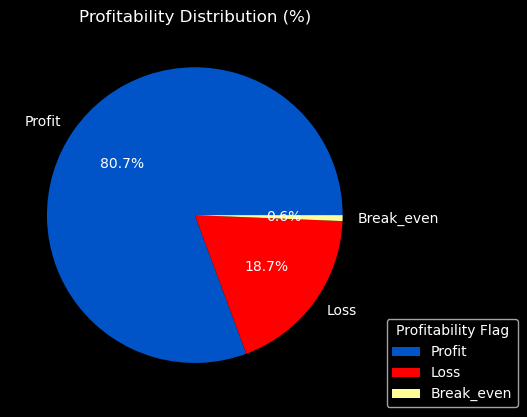

In [14]:
# Visualization of profitability distribution
profit_counts = df['profitability_flag'].value_counts(normalize=True) * 100
profit_counts.plot(
    kind='pie', 
    autopct='%1.1f%%', 
    colors=['#0054C7', danger_color, '#FDFD96'] 
)
plt.ylabel('')
plt.title('Profitability Distribution (%)')

# Add the legend (positioned outside the pie to prevent overlap)
plt.legend(title="Profitability Flag", loc="center left", bbox_to_anchor=(1, 0.1))
plt.show()

In [15]:
def format_func(value):
    if value >= 1e6:
        return f'{value/1e6:.1f}M $' 
    elif value >= 1e3:
        return f'{value/1e3:.1f}K $' 
    else:
        return f'{value:.1f} $'      

delayed_df = df[df['delay'] > 0]
metrics = {}
metrics['Total Orders'] = len(df)
metrics['Late Deliveries'] = len(delayed_df)
metrics['90% Delay (days)'] = delayed_df['delay'].quantile(0.90)
metrics['On Time Delivery %'] = (1 - float(metrics['Late Deliveries']) / metrics['Total Orders']) * 100
metrics['Late Delivery %'] = float(metrics['Late Deliveries']) / metrics['Total Orders'] * 100
metrics['Total Profit'] = format_func(df.loc[df['order_profit_per_order'] > 0, 'order_profit_per_order'].sum())
metrics['Total Loss due to delays'] = format_func(df.loc[df['delay'] > 0, 'order_profit_per_order'].sum())

print('\n--- Business KPIs ---\n')
for k, v in metrics.items():
    if isinstance(v, float):
        print(f"{k}: {v:.2f}") 
    else:
        print(f"{k}: {v}")


--- Business KPIs ---

Total Orders: 172765
Late Deliveries: 94523
90% Delay (days): 3.00
On Time Delivery %: 45.29
Late Delivery %: 54.71
Total Profit: 7.5M $
Total Loss due to delays: 2.1M $


## Profitability vs Delivery Time Analysis

In [16]:
profit_metrics = (df.groupby('delay')['order_profit_per_order']
                    .agg(
                        mean_profit = 'mean',
                        total_profit = 'sum',
                        order_count = 'count'
                    )
                  .reset_index())

In [17]:
profit_metrics

,delay,mean_profit,total_profit,order_count
0,-2,23.360134,4.875961e+05,20873
1,-1,21.604769,4.476292e+05,20719
2,0,22.249118,8.154302e+05,36650
3,1,22.333227,1.194895e+06,53503
4,2,21.128491,5.821110e+05,27551
5,3,20.031412,1.356527e+05,6772
6,4,21.368783,1.431067e+05,6697


In [18]:
delay_distribution = (
    df['delay']
    .value_counts(normalize=True)
    .sort_index() * 100
).reset_index()

In [19]:
delay_distribution

,delay,proportion
0,-2,12.081730
1,-1,11.992591
2,0,21.213788
3,1,30.968657
4,2,15.947096
5,3,3.919775
6,4,3.876364



Profit Metrics By Delay Days:


,delay,mean_profit,total_profit,order_count
0,-2,23.4,487596.1,20873
1,-1,21.6,447629.2,20719
2,0,22.2,815430.2,36650
3,1,22.3,1194894.7,53503
4,2,21.1,582111.0,27551
5,3,20.0,135652.7,6772
6,4,21.4,143106.7,6697



Delay Distribution (%):


,Delay_Days,Percentage
0,-2,12.081730
1,-1,11.992591
2,0,21.213788
3,1,30.968657
4,2,15.947096
5,3,3.919775
6,4,3.876364


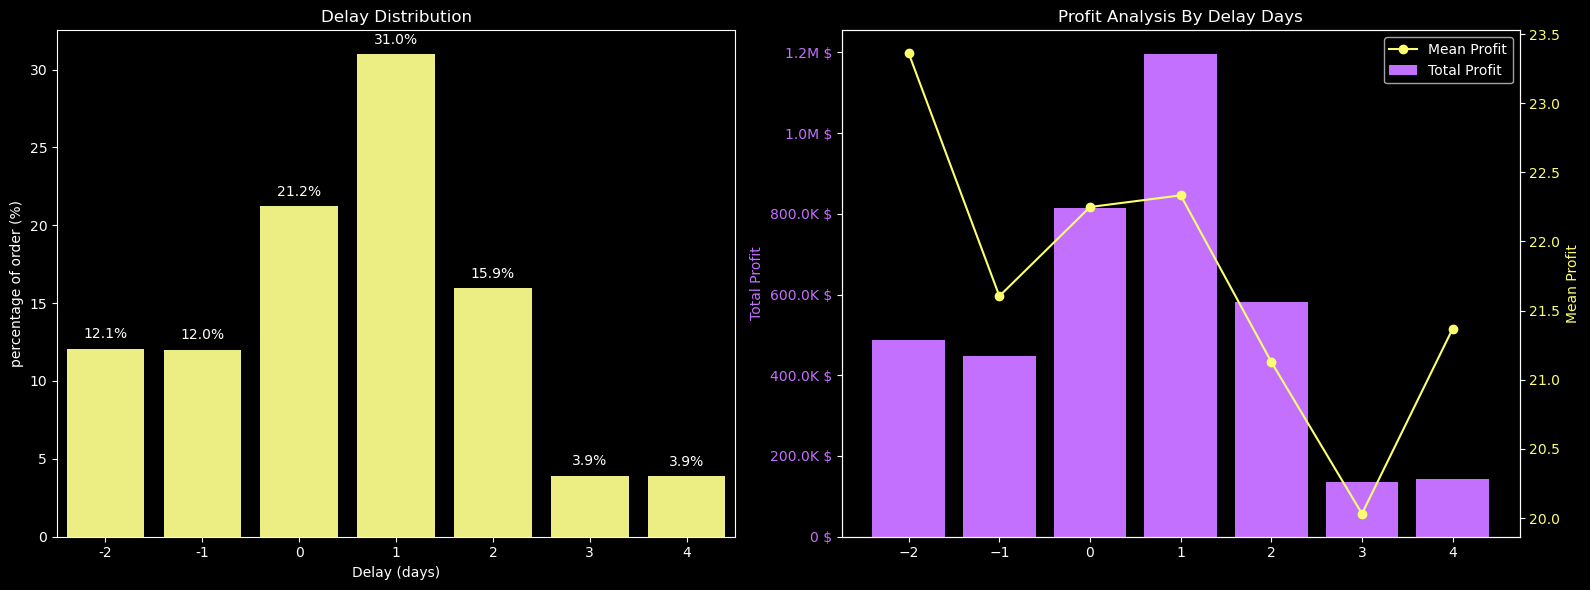

In [20]:
# Corrected spelling of 'columns'
delay_distribution.columns = ['Delay_Days', 'Percentage']

print("\nProfit Metrics By Delay Days:")
display(profit_metrics.round(1))

print("\nDelay Distribution (%):")
display(delay_distribution)


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16,6))

# First subplot : Delay Distribution
sns.barplot(x='Delay_Days', y='Percentage', data=delay_distribution, color=accent_color, ax=ax1)
ax1.set_title('Delay Distribution')
ax1.set_xlabel('Delay (days)')
ax1.set_ylabel('percentage of order (%)')

# Percentage text on bars
for bar in ax1.patches:
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, height + 0.5, f'{height:.1f}%', ha='center', va='bottom')

# Second subplot: Profit Analysis by Delay Days
ax2.set_ylabel("Total Profit", color=primary_color)
ax2.bar(profit_metrics['delay'], profit_metrics['total_profit'], color=primary_color, label='Total Profit')
ax2.tick_params(axis='y', labelcolor=primary_color)

ax3 = ax2.twinx()

ax3.set_xlabel("Delay Days")
ax3.set_ylabel("Mean Profit", color=accent_color)
ax3.plot(profit_metrics['delay'], profit_metrics['mean_profit'], marker='o', label='Mean Profit', color=accent_color)
ax3.tick_params(axis='y', labelcolor=accent_color)

# Format Total Profit axis to k $, M $
from matplotlib.ticker import FuncFormatter

def format_func(value, tick_number):
    if value >= 1e6:
        return f"{value/1e6:.1f}M $"
    elif value >= 1e3:
        return f"{value/1e3:.1f}K $"
    else:
        return f"{value:.0f} $"
ax2.yaxis.set_major_formatter(FuncFormatter(format_func))

ax2.set_title("Profit Analysis By Delay Days")

lines, labels = ax3.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax3.legend(lines + lines2, labels + labels2, loc='upper right')

plt.tight_layout()
plt.show()

## Bottleneck Detection

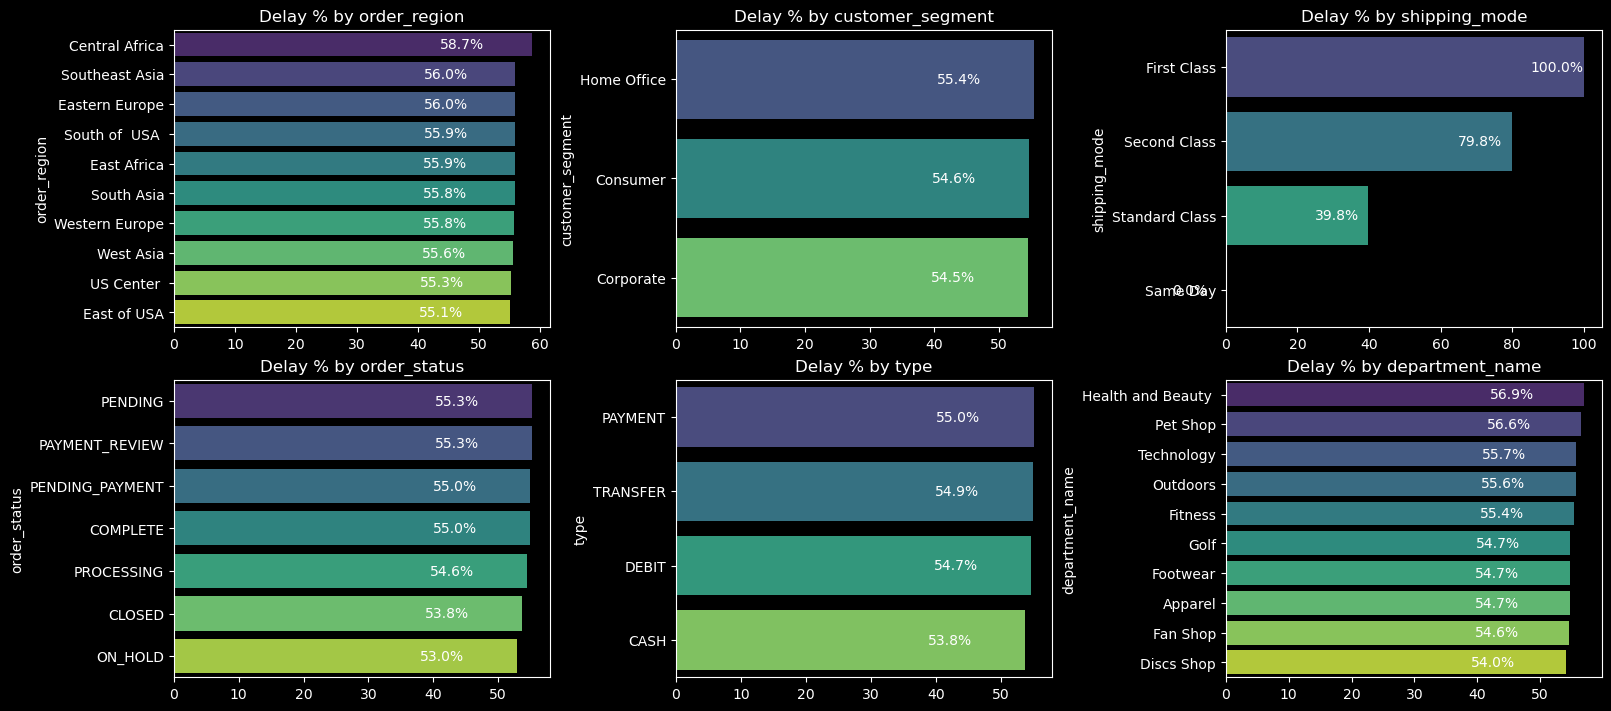

In [21]:
def compute_delay_pct_by_category (category):
    cat_df = df .groupby (category) .agg (
        total_orders=( 'delay', 'count'), 
        late_orders=('is_delayed' , 'sum' )
    ). reset_index()
    cat_df ['delay_pct'] = cat_df['late_orders'] / cat_df['total_orders'] * 100
    cat_df = cat_df.sort_values ('delay_pct', ascending=False) .head (10)
    return cat_df

categories = ['order_region', 'customer_segment', 'shipping_mode', 'order_status', 'type', 'department_name']
fig, axes = plt.subplots(2, 3, figsize=(16, 7), constrained_layout=True)
axes = axes. flatten()

for ax, category in zip(axes, categories):
    cat_df = compute_delay_pct_by_category(category)
    sns. barplot(
        data=cat_df,
        x='delay_pct',
        y=category, ax=ax,
        palette='viridis'
    )
    ax.set_title(f'Delay % by {category}')
    ax.set_xlabel('')
    ax.set_ylabel (category)
    for i, row in cat_df.reset_index().iterrows():
        ax.text(row['delay_pct'] - 15, i, f"{row['delay_pct']:.1f}%", va='center', fontsize=10, color = 'white')

plt.show()

## Root Cause Analysis

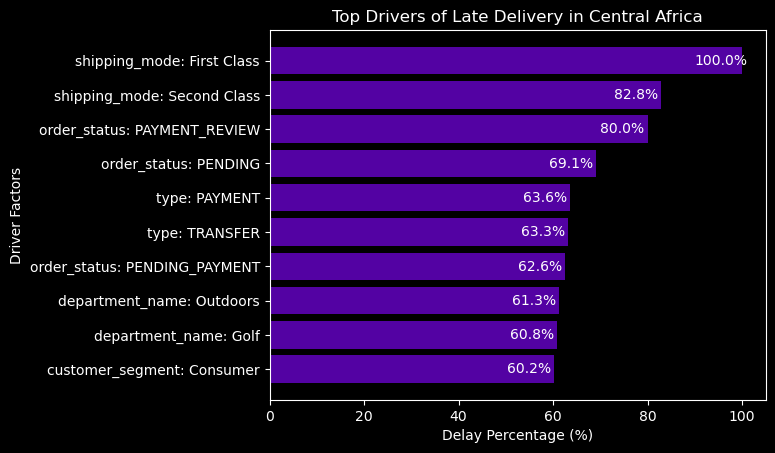

In [22]:
# Top drivers of late delivery by region

def top_drivers_for_region (region):
    df_region = df[df['order_region'] == region].copy()
    
    drivers = ['shipping_mode', 'customer_segment', 'department_name', 'type', 'order_status']
    
    all_factors = []
    for factor in drivers:
        temp = (df_region.groupby(factor)
               .agg(
                   total_orders=( 'delay', 'count'),
                   late_orders=( 'is_delayed', 'sum'), 
                   avg_delay=( 'delay', 'mean')
               )
               .reset_index()
        )
        
            
        temp['delay_pct'] = temp['late_orders'] / temp['total_orders'] * 100
        temp ['Driver'] = factor
        temp ['Factor_Level'] = factor + ": " + temp[factor].astype(str)
     
        all_factors.append(temp[['Driver', 'Factor_Level', 'delay_pct', 'avg_delay', 'total_orders']])

    # Combine all drivers
    final_df = pd.concat(all_factors)
    
    # Top 10 drivers
    top_factors = final_df.sort_values('delay_pct', ascending=False).head (10)
    plt. figure ()

    bars = plt.barh(top_factors ['Factor_Level'], top_factors ['delay_pct'])

    plt.xlabel("Delay Percentage (%)")
    plt.ylabel("Driver Factors")
    plt.title(f"Top Drivers of Late Delivery in {region}") 
    #plt.grid(True, linestyle=':', alpha=0.5)
    plt.gca (). invert_yaxis()
    for bar in bars:
        width = bar.get_width()
        plt.text(width - 10, bar.get_y() + bar.get_height()/2,
                f"{width:.1f}%",
                va='center', fontsize = 10, color = 'White')
plt.show()
top_drivers_for_region('Central Africa')

## Time Based Analysis

In [23]:
# Delay % by Month, Day of Week, Hour
delay_by_month = (
    df.groupby('order_month')['is_delayed']
        .mean()
        .reset_index()
)
delay_by_month['delay_pct'] = delay_by_month['is_delayed'] * 100

delay_by_day = (
    df.groupby('order_day')['is_delayed']
    .mean()
    .reset_index()
)
delay_by_day['delay_pct'] = delay_by_day['is_delayed'] * 100

delay_by_hour = (
    df.groupby('order_hour')['is_delayed']
        .mean()
        .reset_index()
)
delay_by_hour['delay_pct'] = delay_by_hour['is_delayed'] * 100

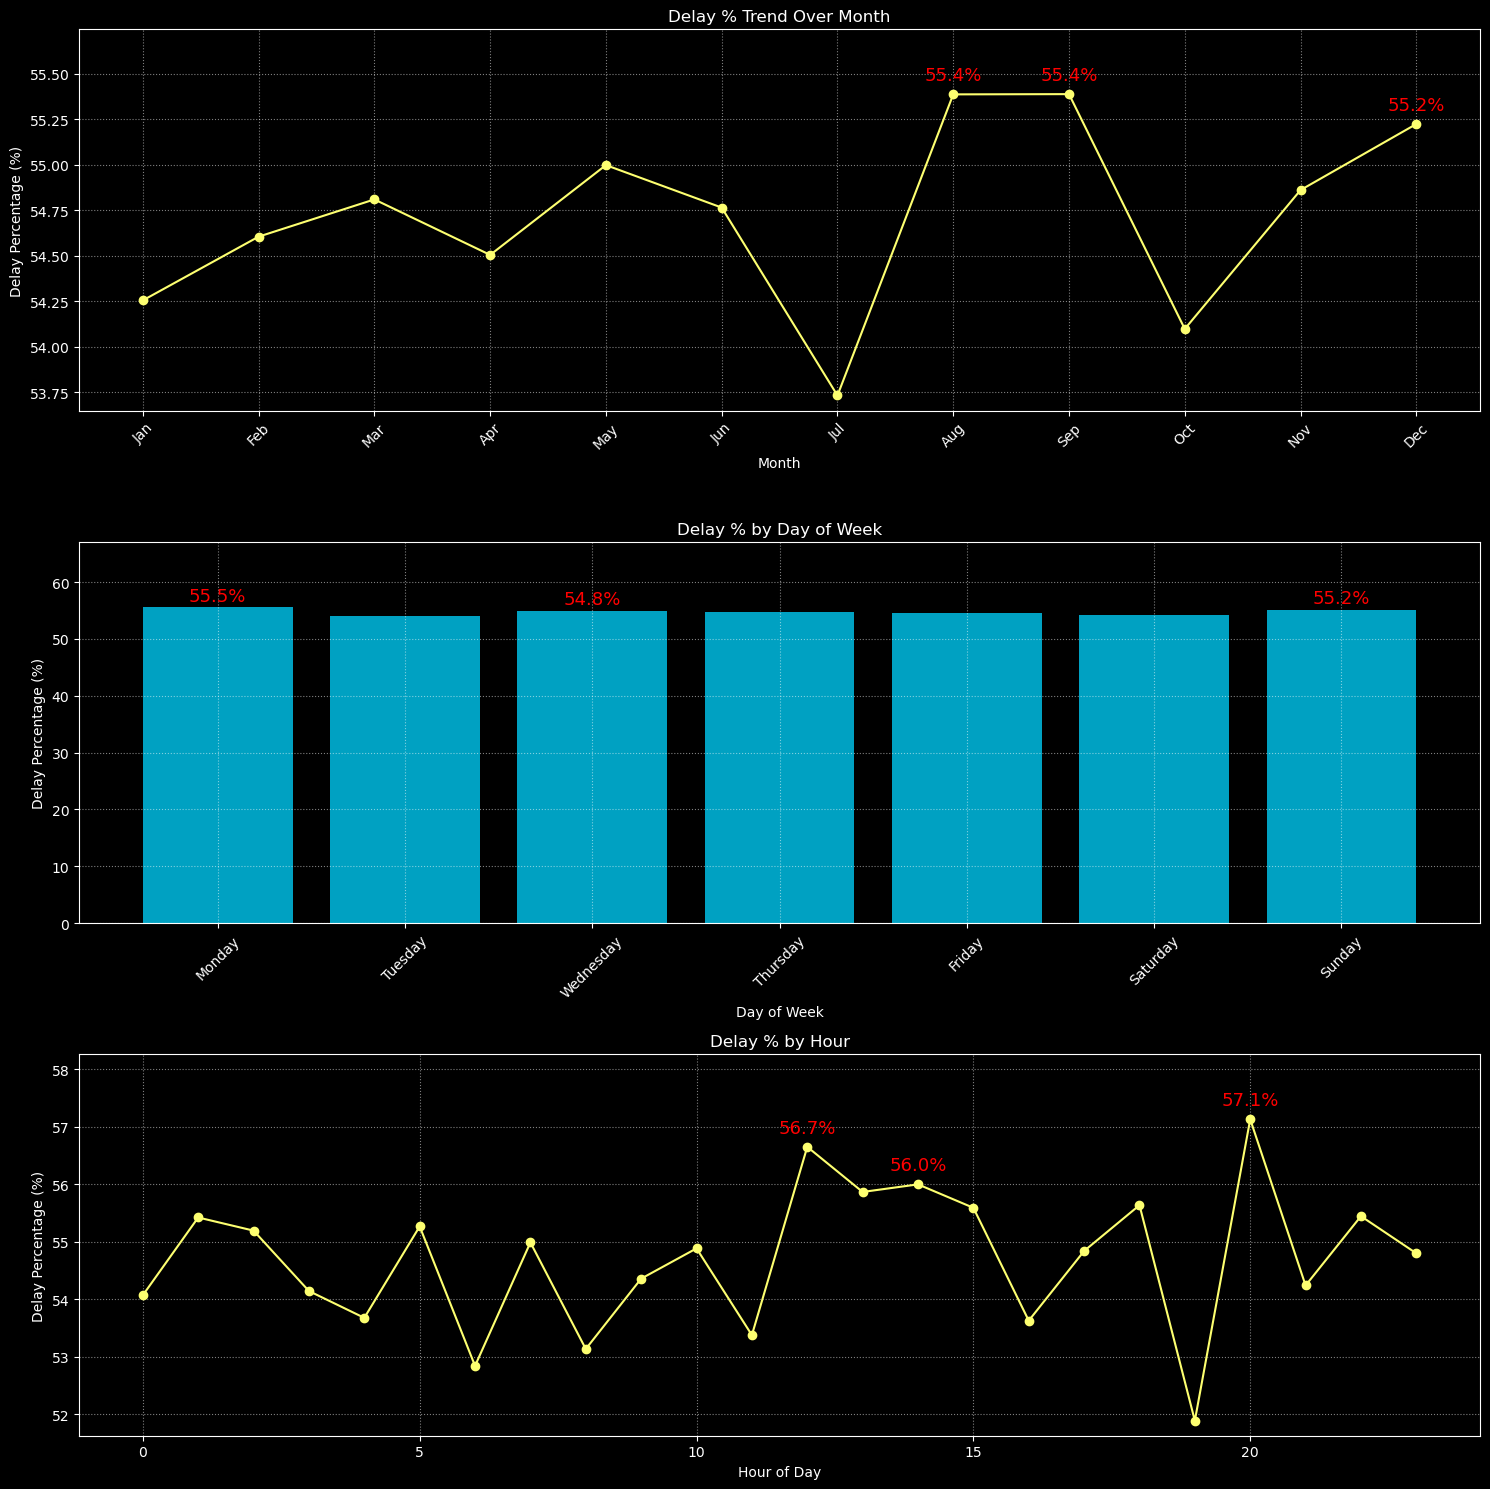

In [35]:
fig, (ax1, ax2, ax3) = plt.subplots(3,1, figsize=(15,15))

# Subplot 1: Delay % Trend Over Month
ax1.plot(delay_by_month['order_month'], delay_by_month['delay_pct'], marker='o', color=accent_color)
ax1.set_xticks(range(1,13))
ax1.set_xticklabels(['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'], rotation=45)
ax1.set_xlabel("Month")
ax1.set_ylabel("Delay Percentage (%)")
ax1.set_title("Delay % Trend Over Month")
ax1.grid(True, linestyle=':', alpha=0.5)

# Annotate top 3 highest
top3_month = delay_by_month.nlargest(3, 'delay_pct')
for _, row in top3_month.iterrows():
    ax1.annotate(f"{row['delay_pct']:.1f}%", (row['order_month'], row['delay_pct']),
                 textcoords="offset points", xytext=(0,10), ha='center', fontsize=13, color=danger_color)

# Subplot 2: Delay % by Day of Week
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
delay_by_day['order_day'] = pd.Categorical(delay_by_day['order_day'], categories=day_order, ordered=True)
delay_by_day = delay_by_day.sort_values('order_day')

ax2.bar(delay_by_day['order_day'], delay_by_day['delay_pct'], color=secondary_color)
ax2.set_xticks(range(len(delay_by_day['order_day'])))
ax2.set_xticklabels(delay_by_day['order_day'], rotation=45)
ax2.set_xlabel("Day of Week")
ax2.set_ylabel("Delay Percentage (%)")
ax2.set_title("Delay % by Day of Week")
ax2.grid(True, linestyle=':', alpha=0.5)

# Annotate top 3 highest bars
top3_day = delay_by_day.nlargest(3, 'delay_pct')
for _, row in top3_day.iterrows(): 
    height = row['delay_pct']
    ax2.text(row['order_day'], height + 0.5, f'{height:.1f}%', ha='center', va='bottom', fontsize=13, color=danger_color)

# Subplot 3: Delay % by Hour
ax3.plot(delay_by_hour['order_hour'], delay_by_hour['delay_pct'], marker='o', color=accent_color)
ax3.set_xlabel("Hour of Day")
ax3.set_ylabel("Delay Percentage (%)")
ax3.set_title("Delay % by Hour")
ax3.grid(True, linestyle=':', alpha=0.5)

# Annotate top 3 highest
top3_hour = delay_by_hour.nlargest(3, 'delay_pct')
for _, row in top3_hour.iterrows():
    ax3.annotate(f"{row['delay_pct']:.1f}%", (row['order_hour'], row['delay_pct']),
                 textcoords="offset points", xytext=(0,10), ha='center', fontsize=13, color=danger_color)

# Expand y-axis limits to make room for data labels
for ax in (ax1, ax2, ax3):
    y_min, y_max = ax.get_ylim()
    ax.set_ylim(y_min, y_max + (y_max - y_min) * 0.15)

plt.tight_layout()
plt.show()

In [25]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, classification_report
from sklearn. ensemble import RandomForestClassifier
from collections import Counter
from imblearn.over_sampling import SMOTE

In [26]:
X = df[['type', 'days_for_shipment_(scheduled)', 'category_name', 'customer_segment', 'department_name', 'order_region','shipping_mode', 'order_month','order_hour']]
y = df['late_delivery_risk']

In [27]:
cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
print('Categorical columns:', cat_cols)

# Frequency encoding (low-dimensional and robust for high-cardinality)
for col in cat_cols:
    freq = X[col].value_counts(normalize=True)
    X[f'{col}_freq'] = X[col].map(freq)

# Keep numeric columns + new encoded features, drop original string categories
X_encoded = X.drop(columns=cat_cols)
print('Shape after freq+target encoding:', X_encoded.shape)

# use encoded features for modeling
X = X_encoded

# train/test split after encoding
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

Categorical columns: ['type', 'category_name', 'customer_segment', 'department_name', 'order_region', 'shipping_mode']
Shape after freq+target encoding: (172765, 9)


In [28]:
y.value_counts()

late_delivery_risk
1    98977
0    73788
Name: count, dtype: int64

In [29]:
# Balancing the training data using SMOTE
print("Before balancing (train):", Counter(y_train))

smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train)

print("After balancing (train):", Counter(y_train_bal))

Before balancing (train): Counter({1: 79182, 0: 59030})
After balancing (train): Counter({0: 79182, 1: 79182})


In [30]:
def evaluate_model(y_true, y_pred, model_name):
    print(f"\n --- {model_name} --- ")
    print("Accuracy:", round(accuracy_score(y_true, y_pred), 2))
    print("Precision:", round(precision_score(y_true, y_pred), 2))
    print("Recall:", round(recall_score(y_true, y_pred),2))
    print("\nClassification Report:\n", classification_report(y_true, y_pred))

In [31]:
# Fit the Random Forest model on balanced data
rf_model_balanced = RandomForestClassifier(random_state=42)
rf_model_balanced.fit(X_train_bal, y_train_bal)

y_pred_rf_balanced = rf_model_balanced.predict(X_test)

evaluate_model(y_test, y_pred_rf_balanced, "Random Forest Classifier")


 --- Random Forest Classifier --- 
Accuracy: 0.74
Precision: 0.79
Recall: 0.75

Classification Report:
               precision    recall  f1-score   support

           0       0.68      0.73      0.70     14758
           1       0.79      0.75      0.77     19795

    accuracy                           0.74     34553
   macro avg       0.73      0.74      0.73     34553
weighted avg       0.74      0.74      0.74     34553



In [32]:
import pickle

# Define the filename for your model
model_filename = 'rf_model_balanced.pkl'

# Save the model to disk in write-binary ('wb') mode
with open(model_filename, 'wb') as file:
    pickle.dump(rf_model_balanced, file)

print(f"Model successfully saved as {model_filename}")

Model successfully saved as rf_model_balanced.pkl


In [33]:
df.columns

Index(['type', 'days_for_shipping_(real)', 'days_for_shipment_(scheduled)',
       'sales_per_customer', 'delivery_status', 'late_delivery_risk',
       'category_name', 'customer_country', 'customer_segment',
       'department_name', 'order_date_(dateorders)', 'order_item_profit_ratio',
       'sales', 'order_profit_per_order', 'order_region', 'order_status',
       'product_name', 'product_price', 'shipping_date_(dateorders)',
       'shipping_mode', 'order_processing_time', 'delay', 'is_delayed',
       'order_month', 'order_day', 'order_hour', 'profitability_flag'],
      dtype='object')